# Course 3 — Nonlinear Kalman Filters

*My study notes in simple language. No long derivations — just the ideas, the key equations, and Python demos.*

**Contents**
1. Extended Kalman filter (EKF)
2. Sigma-point Kalman filter (SPKF / UKF / CDKF)
3. Improvements: iterated EKF, cubature KF, adaptive EKF
4. Estimating model parameters (and states + parameters together)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import cholesky, block_diag

np.random.seed(3)
plt.rcParams["figure.figsize"] = (9, 3.5)
plt.rcParams["axes.grid"] = True
rms = lambda e: np.sqrt(np.mean(np.asarray(e)**2))

---
## Why nonlinear filters?
Real systems are rarely linear. The general model is
$$x_k = f(x_{k-1}, u_{k-1}, w_{k-1}),\qquad z_k = h(x_k, u_k, v_k)$$
Problem: when a Gaussian goes through a nonlinear function, the result is **not Gaussian**, and its mean is **not** simply $f(\text{mean})$.
So the exact KF equations no longer apply — we need approximations. The **six generic steps** from Course 2 stay the same; only the way we compute the means and covariances changes.

| Method | How it approximates |
|---|---|
| **EKF** | Linearise $f$ and $h$ around the current estimate (Taylor series, Jacobians) |
| **SPKF** | Push a few carefully chosen "sigma points" through the real nonlinear functions |
| **Particle filter** | Push many random samples through (Course 4) |

### Example system used in this notebook
A mass on a **nonlinear (hardening) spring** with damping, driven by a force.
State $x = [y,\ \dot y]$ (position, velocity). Discretised with Euler's rule:
$$f(x_k,u_k,w_k) = \begin{bmatrix} x_1 + \Delta t\,x_2 \\ x_2 + \Delta t\left(-\frac{b}{m}x_2 - \frac{k_1}{m}x_1 - \frac{k_2}{m}x_1^3\right) + \frac{\Delta t}{m}(u_k + w_k)\end{bmatrix}$$
**Nonlinear sensor:** we measure the *angle* to the mass from a point a distance $d$ away:
$$z_k = \arctan\!\left(\frac{x_1}{d}\right) + v_k$$

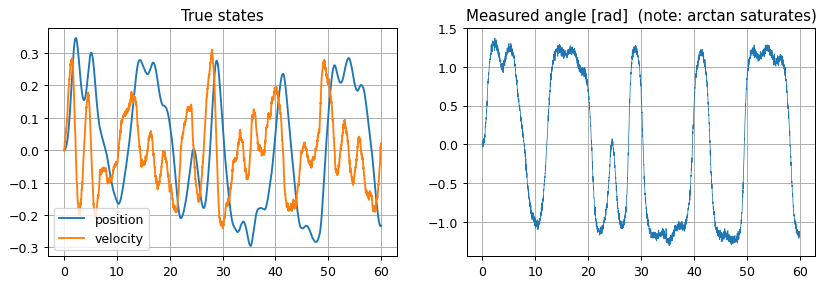

In [2]:
m_, b_, k1_, k2_, d_ = 1.0, 0.4, 1.0, 20.0, 0.1
dt = 0.02
SigmaW = 0.2**2           # process-noise variance (force)
SigmaV = 0.03**2          # sensor-noise variance (rad)

def f(x, u, w, k1=k1_):
    x1, x2 = x[0], x[1]
    return np.array([x1 + dt*x2,
                     x2 + dt*(-b_/m_*x2 - k1/m_*x1 - k2_/m_*x1**3) + dt/m_*(u + w)])

def h(x, u, v):
    return np.arctan(x[0]/d_) + v

# simulate the true system
N = 3000
t = np.arange(N)*dt
u = 0.4*np.sin(0.5*t) + 0.2*np.sign(np.sin(0.13*t))
x = np.zeros((2, N)); z = np.zeros(N)
for k in range(N):
    if k > 0:
        x[:, k] = f(x[:, k-1], u[k-1], np.sqrt(SigmaW)*np.random.randn())
    z[k] = h(x[:, k], u[k], np.sqrt(SigmaV)*np.random.randn())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
ax[0].plot(t, x[0], label="position"); ax[0].plot(t, x[1], label="velocity"); ax[0].legend(); ax[0].set_title("True states")
ax[1].plot(t, z, lw=0.6); ax[1].set_title("Measured angle [rad]  (note: arctan saturates)"); plt.show()

---
## 1. Extended Kalman filter (EKF)

**Two approximations:**
1. The expected value of a function ≈ function of the expected value: $\mathbb{E}[f(x)] \approx f(\mathbb{E}[x])$
2. Covariances are propagated with a **first-order Taylor expansion** (Jacobians).

### Jacobians needed
$$\hat A_k = \frac{\partial f}{\partial x}\Big|_{\hat x_k^+},\quad \hat B_k = \frac{\partial f}{\partial w}\Big|_{\bar w},\quad \hat C_k = \frac{\partial h}{\partial x}\Big|_{\hat x_k^-},\quad \hat D_k = \frac{\partial h}{\partial v}\Big|_{\bar v}$$

### EKF steps
| Step | Equation |
|---|---|
| 1a | $\hat x_k^- = f(\hat x_{k-1}^+, u_{k-1}, \bar w)$ |
| 1b | $\Sigma_{\tilde x,k}^- = \hat A\Sigma_{\tilde x,k-1}^+\hat A^T + \hat B\Sigma_{\tilde w}\hat B^T$ |
| 1c | $\hat z_k = h(\hat x_k^-, u_k, \bar v)$ |
| 2a | $L_k = \Sigma^-\hat C^T(\hat C\Sigma^-\hat C^T + \hat D\Sigma_{\tilde v}\hat D^T)^{-1}$ |
| 2b | $\hat x_k^+ = \hat x_k^- + L_k(z_k - \hat z_k)$ |
| 2c | $\Sigma^+ = (I - L_k\hat C)\Sigma^-$ |

It looks like the linear KF, but the **state and output predictions use the real nonlinear functions**, and the matrices are recomputed every step.

### Jacobians for our example
$$\hat A = \begin{bmatrix}1 & \Delta t\\ -\frac{\Delta t}{m}(k_1 + 3k_2\hat x_1^2) & 1 - \frac{b\Delta t}{m}\end{bmatrix},\quad
\hat B = \begin{bmatrix}0\\ \Delta t/m\end{bmatrix},\quad
\hat C = \begin{bmatrix}\frac{d}{d^2 + \hat x_1^2} & 0\end{bmatrix},\quad \hat D = 1$$

**Weak points of EKF:** needs derivatives (can be hard / error-prone), and linearisation can be poor for strong nonlinearities → biased estimates, overconfident bounds, even divergence.

EKF     RMS err = 0.0875   inside bounds: pos 97.8%  vel 98.3%


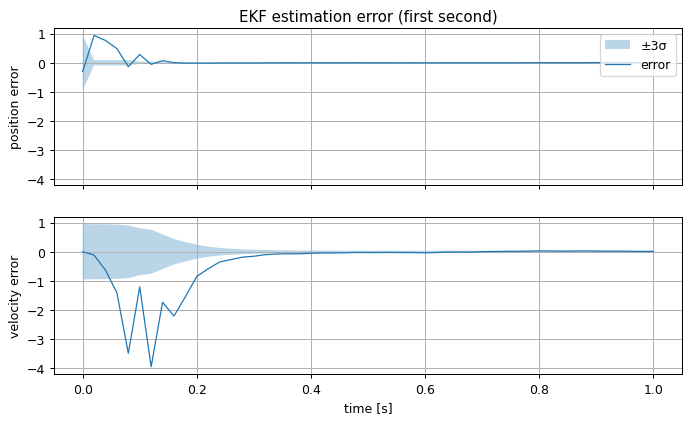

In [3]:
def jac_A(x, k1=k1_):
    return np.array([[1, dt], [-dt/m_*(k1 + 3*k2_*x[0]**2), 1 - b_*dt/m_]])
Bw = np.array([[0], [dt/m_]])
def jac_C(x):
    return np.array([[d_/(d_**2 + x[0]**2), 0]])

def run_ekf(z, u, x0, P0):
    xhat, P = x0.copy(), P0.copy()
    xs, bs = np.zeros((2, len(z))), np.zeros((2, len(z)))
    xs[:, 0], bs[:, 0] = xhat, 3*np.sqrt(np.diag(P))
    for k in range(1, len(z)):
        A = jac_A(xhat)                                     # linearise at x^+_{k-1}
        xhat = f(xhat, u[k-1], 0.0)                         # 1a
        P = A @ P @ A.T + Bw @ Bw.T * SigmaW                # 1b
        zhat = h(xhat, u[k], 0.0)                           # 1c
        Ck = jac_C(xhat)
        L = P @ Ck.T / (Ck @ P @ Ck.T + SigmaV)             # 2a
        xhat = xhat + (L * (z[k] - zhat)).ravel()           # 2b
        P = (np.eye(2) - L @ Ck) @ P                        # 2c
        xs[:, k], bs[:, k] = xhat, 3*np.sqrt(np.diag(P))
    return xs, bs

# the filter starts with a WRONG initial position (0.3 m, truth is 0) — a hard test
x0 = np.array([0.3, 0.0]); P0 = np.diag([0.1, 0.1])
xe, be = run_ekf(z, u, x0, P0)

def plot_est(xhat, bnd, title, tmax=1.0):
    # zoom on the start-up, where the filters differ most
    w = t <= tmax
    fig, ax = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
    for i, nm in enumerate(["position", "velocity"]):
        ax[i].fill_between(t[w], -bnd[i, w], bnd[i, w], alpha=0.3, label="±3σ")
        ax[i].plot(t[w], x[i, w] - xhat[i, w], lw=1, label="error")
        ax[i].set_ylim(-4.2, 1.2)
        ax[i].set_ylabel(nm + " error")
    ax[0].legend(loc="upper right"); ax[0].set_title(title); ax[1].set_xlabel("time [s]")

def report(name, xhat, bnd):
    inside = np.mean(np.abs(x - xhat) <= bnd, axis=1)*100
    print(f"{name:6s}  RMS err = {rms(x - xhat):.4f}   inside bounds: pos {inside[0]:.1f}%  vel {inside[1]:.1f}%")

plot_est(xe, be, "EKF estimation error (first second)"); plt.show()
report("EKF", xe, be)

**What to notice:** with a wrong initial guess the EKF linearises around a bad point. Its errors jump far outside the ±3σ bounds for a while (the filter is *overconfident*) before it recovers. This is the typical EKF weakness.

---
## 2. Sigma-point Kalman filter (SPKF)

### Idea
"It is easier to approximate a probability distribution than a nonlinear function."
Instead of linearising, pick a small set of **sigma points** that have exactly the right mean and covariance, send each one through the **true** nonlinear function, and compute the mean and covariance of the outputs.

For an $L$-dimensional variable with mean $\bar x$ and covariance $\Sigma$ (Cholesky factor $\sqrt\Sigma$):
$$\mathcal X = \left\{\bar x,\ \ \bar x + \gamma\sqrt{\Sigma},\ \ \bar x - \gamma\sqrt{\Sigma}\right\}\quad (2L+1 \text{ points})$$
Output statistics:
$$\bar y \approx \sum_i \alpha_i^{(m)} \mathcal Y_i,\qquad \Sigma_y \approx \sum_i \alpha_i^{(c)}(\mathcal Y_i - \bar y)(\mathcal Y_i - \bar y)^T$$

Two popular weight choices:
| | $\gamma$ | $\alpha_0^{(m)}$ | $\alpha_i^{(m)}$ |
|---|---|---|---|
| **UKF** (unscented) | $\sqrt{L+\lambda}$ | $\frac{\lambda}{L+\lambda}$ | $\frac{1}{2(L+\lambda)}$ |
| **CDKF** (central difference) | $h = \sqrt3$ | $\frac{h^2 - L}{h^2}$ | $\frac{1}{2h^2}$ |

Accuracy: mean is correct to 2nd order (EKF only 1st), **no derivatives needed**, similar computational cost.

### Quick demo: unscented transform vs. linearisation

true y-mean 0.872 | EKF 1.000 | SPKF 0.872


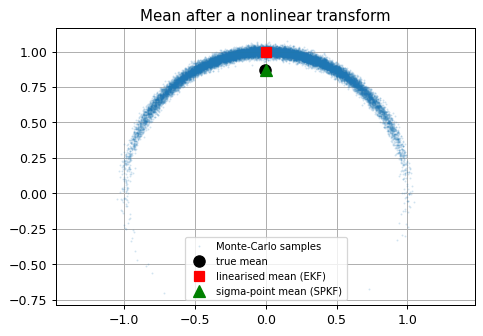

In [4]:
def sigma_points(xbar, P, h_=np.sqrt(3)):
    # CDKF-style sigma points and weights
    L = len(xbar); S = cholesky(P, lower=True)
    X = np.hstack([xbar[:, None], xbar[:, None] + h_*S, xbar[:, None] - h_*S])
    wm = np.full(2*L+1, 1/(2*h_**2)); wm[0] = (h_**2 - L)/h_**2
    return X, wm, wm.copy()

# Polar -> Cartesian: a classic strongly nonlinear transform
mean_p = np.array([1.0, np.pi/2]); P_p = np.diag([0.02**2, np.deg2rad(30)**2])
g = lambda p: np.array([p[0]*np.cos(p[1]), p[0]*np.sin(p[1])])

samples = mean_p[:, None] + cholesky(P_p, lower=True) @ np.random.randn(2, 20000)
Y = g(samples); mc_mean = Y.mean(axis=1)
lin_mean = g(mean_p)                                            # EKF-style
X, wm, wc = sigma_points(mean_p, P_p); Ys = g(X); sp_mean = Ys @ wm   # SPKF-style

plt.figure(figsize=(6, 4))
plt.plot(Y[0], Y[1], '.', ms=1, alpha=0.2, label="Monte-Carlo samples")
plt.plot(*mc_mean, 'ko', ms=9, label="true mean")
plt.plot(*lin_mean, 'rs', ms=8, label="linearised mean (EKF)")
plt.plot(*sp_mean, 'g^', ms=9, label="sigma-point mean (SPKF)")
plt.axis("equal"); plt.legend(fontsize=8); plt.title("Mean after a nonlinear transform"); plt.show()
print("true y-mean %.3f | EKF %.3f | SPKF %.3f" % (mc_mean[1], lin_mean[1], sp_mean[1]))

### SPKF steps (with an augmented state)
To handle noises that enter nonlinearly, build an **augmented** vector $x^a = [x;\ w;\ v]$ with covariance $\text{blkdiag}(\Sigma_{\tilde x}^+, \Sigma_{\tilde w}, \Sigma_{\tilde v})$.

| Step | What happens |
|---|---|
| 1a | make sigma points of $x^a$, push through $f$: $\mathcal X_{k,i}^{x,-} = f(\mathcal X_{k-1,i}^{x,+}, u, \mathcal X_{k-1,i}^{w,+})$; mean = weighted sum |
| 1b | $\Sigma_{\tilde x}^-$ = weighted outer products of the spread |
| 1c | push through $h$: $\mathcal Z_{k,i} = h(\mathcal X_{k,i}^{x,-}, u, \mathcal X_{k-1,i}^{v,+})$; $\hat z$ = weighted sum |
| 2a | $\Sigma_{\tilde z}$ and $\Sigma_{\tilde x\tilde z}$ from the points → $L = \Sigma_{\tilde x\tilde z}\Sigma_{\tilde z}^{-1}$ |
| 2b | $\hat x^+ = \hat x^- + L(z - \hat z)$ |
| 2c | $\Sigma^+ = \Sigma^- - L\Sigma_{\tilde z}L^T$ |

EKF     RMS err = 0.0875   inside bounds: pos 97.8%  vel 98.3%
SPKF    RMS err = 0.0130   inside bounds: pos 98.2%  vel 99.0%


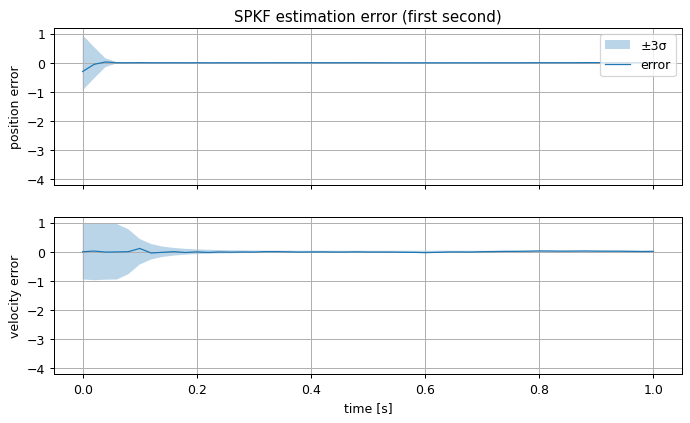

In [5]:
def run_spkf(z, u, x0, P0):
    nx = 2; xhat, P = x0.copy(), P0.copy()
    xs, bs = np.zeros((2, len(z))), np.zeros((2, len(z)))
    xs[:, 0], bs[:, 0] = xhat, 3*np.sqrt(np.diag(P))
    for k in range(1, len(z)):
        xa = np.concatenate([xhat, [0.0, 0.0]])                  # [x; w; v]
        Pa = block_diag(P, SigmaW, SigmaV)
        X, wm, wc = sigma_points(xa, Pa)
        Xx = np.array([f(X[:nx, i], u[k-1], X[nx, i]) for i in range(X.shape[1])]).T   # 1a
        xhat = Xx @ wm
        dX = Xx - xhat[:, None]; P = (wc*dX) @ dX.T                                    # 1b
        Z = np.array([h(Xx[:, i], u[k], X[nx+1, i]) for i in range(X.shape[1])])       # 1c
        zhat = Z @ wm; dZ = Z - zhat
        Sz = np.sum(wc*dZ*dZ); Sxz = (wc*dX) @ dZ                                      # 2a
        L = Sxz / Sz
        xhat = xhat + L*(z[k] - zhat)                                                  # 2b
        P = P - np.outer(L, L)*Sz; P = 0.5*(P + P.T)                                   # 2c
        xs[:, k], bs[:, k] = xhat, 3*np.sqrt(np.diag(P))
    return xs, bs

xsp, bsp = run_spkf(z, u, x0, P0)
plot_est(xsp, bsp, "SPKF estimation error (first second)"); plt.show()
report("EKF", xe, be); report("SPKF", xsp, bsp)

**Result:** the SPKF handles the same bad start smoothly, and its overall RMS error is several times smaller — with no Jacobians at all.

---
## 3. Improvements to EKF and SPKF

### 3.1 Iterated EKF (IEKF)
When the **measurement** equation is very nonlinear, linearising once around $\hat x^-$ can be poor.
IEKF repeats the measurement update a few times, re-linearising $h$ around the newest estimate each time:
$$\hat x^{(i+1)} = \hat x^- + L^{(i)}\left(z - h(\hat x^{(i)}) - \hat C^{(i)}(\hat x^- - \hat x^{(i)})\right)$$
Stop when the change is tiny or after a fixed number of iterations. The prediction step is the same as EKF.

In [6]:
def run_iekf(z, u, x0, P0, n_iter=5):
    xhat, P = x0.copy(), P0.copy()
    xs, bs = np.zeros((2, len(z))), np.zeros((2, len(z)))
    xs[:, 0], bs[:, 0] = xhat, 3*np.sqrt(np.diag(P))
    for k in range(1, len(z)):
        A = jac_A(xhat); xpred = f(xhat, u[k-1], 0.0)
        Pm = A @ P @ A.T + Bw @ Bw.T*SigmaW
        xi = xpred.copy()
        for _ in range(n_iter):
            Ci = jac_C(xi)
            L = Pm @ Ci.T / (Ci @ Pm @ Ci.T + SigmaV)
            xi = xpred + (L*(z[k] - h(xi, u[k], 0.0) - Ci @ (xpred - xi))).ravel()
        xhat, P = xi, (np.eye(2) - L @ Ci) @ Pm
        xs[:, k], bs[:, k] = xhat, 3*np.sqrt(np.diag(P))
    return xs, bs

xie, bie = run_iekf(z, u, x0, P0)
report("EKF", xe, be); report("IEKF", xie, bie)

EKF     RMS err = 0.0875   inside bounds: pos 97.8%  vel 98.3%
IEKF    RMS err = 0.0129   inside bounds: pos 98.3%  vel 99.0%


### 3.2 Simpler SPKF when noises are additive
If $x_k = f(x_{k-1}, u) + w$ and $z_k = h(x_k, u) + v$, we don't need to augment the state.
Make sigma points of $x$ only, then simply **add** $\Sigma_{\tilde w}$ to the predicted covariance and $\Sigma_{\tilde v}$ to $\Sigma_{\tilde z}$. Fewer points → faster.

### 3.3 Cubature Kalman filter (CKF)
A special additive-noise SPKF based on a spherical–radial cubature rule:
- $2n$ points: $\hat x \pm \sqrt{n}\,\sqrt{\Sigma}$ (columns), no centre point
- all weights equal: $1/(2n)$
- weights are never negative → numerically well-behaved in high dimensions.

In [7]:
def run_ckf(z, u, x0, P0):
    n = 2; xhat, P = x0.copy(), P0.copy()
    Q = (Bw @ Bw.T)*SigmaW + 1e-12*np.eye(2)          # process noise treated as additive
    xs, bs = np.zeros((2, len(z))), np.zeros((2, len(z)))
    xs[:, 0], bs[:, 0] = xhat, 3*np.sqrt(np.diag(P))
    for k in range(1, len(z)):
        S = cholesky(P, lower=True)
        X = np.hstack([xhat[:, None] + np.sqrt(n)*S, xhat[:, None] - np.sqrt(n)*S])
        Xp = np.array([f(X[:, i], u[k-1], 0.0) for i in range(2*n)]).T
        xhat = Xp.mean(axis=1); dX = Xp - xhat[:, None]
        P = dX @ dX.T/(2*n) + Q
        S = cholesky(P, lower=True)                   # redraw points for the update
        X = np.hstack([xhat[:, None] + np.sqrt(n)*S, xhat[:, None] - np.sqrt(n)*S])
        Z = np.array([h(X[:, i], u[k], 0.0) for i in range(2*n)])
        zhat = Z.mean(); dZ = Z - zhat; dX = X - xhat[:, None]
        Sz = np.mean(dZ**2) + SigmaV; Sxz = dX @ dZ/(2*n)
        L = Sxz/Sz
        xhat = xhat + L*(z[k] - zhat); P = P - np.outer(L, L)*Sz; P = 0.5*(P + P.T)
        xs[:, k], bs[:, k] = xhat, 3*np.sqrt(np.diag(P))
    return xs, bs

xck, bck = run_ckf(z, u, x0, P0)
report("CKF", xck, bck)

CKF     RMS err = 0.0130   inside bounds: pos 98.2%  vel 99.0%


### 3.4 Adaptive EKF (AEKF) — learning the noise covariances
Often we don't know $\Sigma_{\tilde w}$ and $\Sigma_{\tilde v}$ well. An adaptive filter **estimates them online** from the data (covariance matching). A simple, popular version uses a forgetting factor $\alpha$ (e.g. 0.3–0.99):
- **Sensor noise** from the *residual* after correction, $\epsilon_k = z_k - h(\hat x_k^+)$:
$$\Sigma_{\tilde v} \leftarrow \alpha\Sigma_{\tilde v} + (1-\alpha)(\epsilon_k\epsilon_k^T + \hat C\Sigma^+\hat C^T)$$
- **Process noise** from the *innovation* $r_k$:
$$\Sigma_{w}^{x} \leftarrow \alpha\Sigma_{w}^{x} + (1-\alpha)(L_k r_k r_k^T L_k^T)$$

Below the filter starts with a sensor-noise guess **100× too large** and adapts toward the true value.

final σ_v estimate: 0.0290   (true 0.0300)


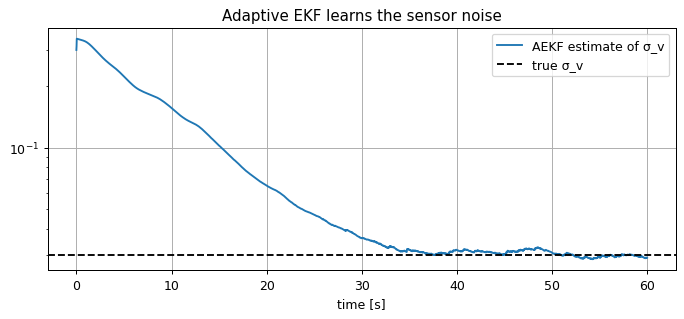

In [8]:
def run_aekf(z, u, x0, P0, SigmaV0, alpha=0.995):
    xhat, P = x0.copy(), P0.copy()
    Qx = (Bw @ Bw.T)*SigmaW; Rv = SigmaV0
    xs = np.zeros((2, len(z))); Rhist = np.zeros(len(z)); Rhist[0] = Rv
    for k in range(1, len(z)):
        A = jac_A(xhat); xhat = f(xhat, u[k-1], 0.0)
        P = A @ P @ A.T + Qx
        Ck = jac_C(xhat); r = z[k] - h(xhat, u[k], 0.0)
        L = P @ Ck.T / (Ck @ P @ Ck.T + Rv)
        xhat = xhat + (L*r).ravel(); P = (np.eye(2) - L @ Ck) @ P
        eps = z[k] - h(xhat, u[k], 0.0); Ck = jac_C(xhat)
        Rv = alpha*Rv + (1-alpha)*(eps**2 + (Ck @ P @ Ck.T).item())
        Qx = alpha*Qx + (1-alpha)*(L @ L.T)*r**2
        xs[:, k], Rhist[k] = xhat, Rv
    return xs, Rhist

xa, Rh = run_aekf(z, u, x0, P0, SigmaV0=100*SigmaV)
plt.semilogy(t, np.sqrt(Rh), label="AEKF estimate of σ_v")
plt.axhline(np.sqrt(SigmaV), color='k', ls='--', label="true σ_v")
plt.legend(); plt.xlabel("time [s]"); plt.title("Adaptive EKF learns the sensor noise"); plt.show()
print("final σ_v estimate: %.4f   (true %.4f)" % (np.sqrt(Rh[-1]), np.sqrt(SigmaV)))

---
## 4. Parameter estimation

Models have parameters (spring constant, battery capacity, resistance …) that are unknown or **slowly change** (ageing). A KF can estimate them too.

### Parameter-only estimation
Treat the parameter vector $\theta$ as a state that changes as a slow **random walk**:
$$\theta_k = \theta_{k-1} + r_{k-1},\qquad d_k = g(x_k, u_k, \theta_k) + e_k$$
- $r_k$: small fictitious noise that lets $\theta$ move (tuning knob: bigger → faster tracking, noisier).
- $d_k$: the measured output that depends on $\theta$.
- The prediction step is trivial ($\hat\theta^- = \hat\theta^+$), the correction uses the output model.
- **EKF version:** needs $\frac{dg}{d\theta}$ — a *total* derivative, because $x_k$ also depends on $\theta$ through past dynamics (computed recursively).
- **SPKF version:** no derivatives; sigma points of $\theta$ are run through the model.

### Joint estimation (states + parameters together)
Stack them into one augmented state and run one filter:
$$X_k = \begin{bmatrix}x_k\\ \theta_k\end{bmatrix},\qquad X_k = \begin{bmatrix} f(x_{k-1}, u_{k-1}, w_{k-1}, \theta_{k-1}) \\ \theta_{k-1} + r_{k-1}\end{bmatrix}$$
Simple to code; even a linear system becomes nonlinear (products of states and parameters), so EKF/SPKF is needed.
(Alternative: **dual estimation** — two separate filters, one for $x$ and one for $\theta$, exchanging estimates. Cheaper when there are many states.)

### Demo: joint EKF estimating the linear spring constant $k_1$
True $k_1 = 1.0$, filter starts with $k_1 = 0.3$. The only new Jacobian entry is $\partial f_2/\partial k_1 = -\Delta t\,x_1/m$.

final k1 estimate: 0.977 ± 0.065 (3σ)


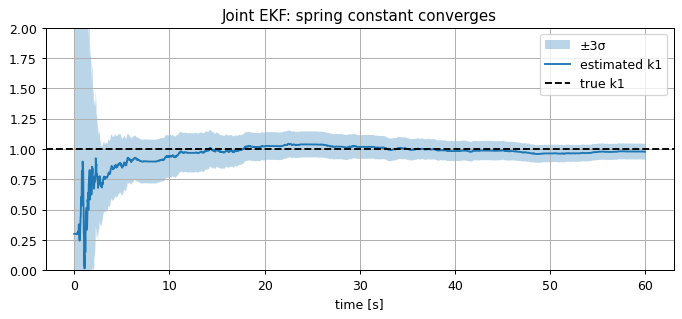

In [9]:
def run_joint_ekf(z, u, k1_guess):
    X = np.array([0.0, 0.0, k1_guess])
    P = np.diag([0.1, 0.1, 1.0])
    Q = block_diag((Bw @ Bw.T)*SigmaW, 1e-8)       # small random walk on k1
    Xs, Bs = np.zeros((3, len(z))), np.zeros((3, len(z)))
    Xs[:, 0], Bs[:, 0] = X, 3*np.sqrt(np.diag(P))
    for k in range(1, len(z)):
        x1, x2, kk = X
        A = np.array([[1, dt, 0],
                      [-dt/m_*(kk + 3*k2_*x1**2), 1 - b_*dt/m_, -dt*x1/m_],
                      [0, 0, 1]])
        X = np.concatenate([f(X[:2], u[k-1], 0.0, k1=kk), [kk]])
        P = A @ P @ A.T + Q
        Ck = np.array([[d_/(d_**2 + X[0]**2), 0, 0]])
        L = P @ Ck.T / (Ck @ P @ Ck.T + SigmaV)
        X = X + (L*(z[k] - h(X, u[k], 0.0))).ravel(); P = (np.eye(3) - L @ Ck) @ P
        Xs[:, k], Bs[:, k] = X, 3*np.sqrt(np.diag(P))
    return Xs, Bs

Xj, Bj = run_joint_ekf(z, u, k1_guess=0.3)
plt.fill_between(t, Xj[2]-Bj[2], Xj[2]+Bj[2], alpha=0.3, label="±3σ")
plt.plot(t, Xj[2], label="estimated k1"); plt.axhline(k1_, color='k', ls='--', label="true k1")
plt.ylim(0, 2); plt.legend(); plt.xlabel("time [s]"); plt.title("Joint EKF: spring constant converges"); plt.show()
print("final k1 estimate: %.3f ± %.3f (3σ)" % (Xj[2, -1], Bj[2, -1]))

---
## Summary
| Filter | Needs derivatives? | Accuracy | Notes |
|---|---|---|---|
| EKF | yes (Jacobians) | 1st order | simple, standard, can be overconfident |
| IEKF | yes | better for nonlinear measurements | a few extra iterations per step |
| SPKF (UKF/CDKF) | no | 2nd order mean | same cost order as EKF, usually more robust |
| CKF | no | similar to SPKF | equal positive weights, additive noise |
| AEKF | yes | — | learns noise covariances online |

- All of them use the **same six steps**; only the way of computing means/covariances differs.
- Parameters can be estimated by treating them as slowly-varying states (**random walk**) — alone, jointly with the states, or with dual filters.
- Typical use case: battery management — joint/dual estimation of SoC (state) and capacity/resistance (parameters, for SoH).